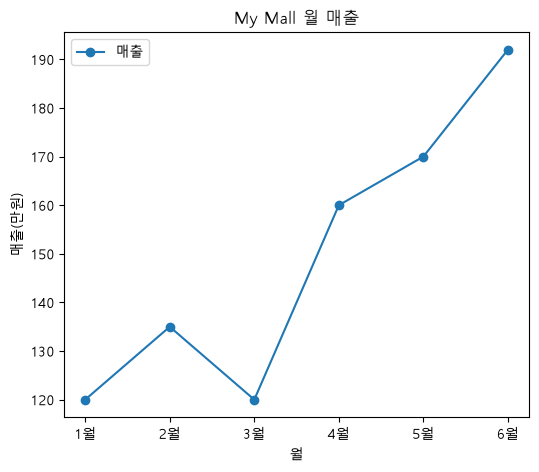

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns   # 시각적 자료의 통계 부분 담당
import matplotlib.pyplot as plt
# import platform

# 한글 폰트
plt.rcParams["font.family"] = "Malgun Gothic"

# Figure(캔버스), Axes(그래프)
fig, ax = plt.subplots(figsize=(6,5))
# x축 데이터 (월)
months = ["1월", "2월", "3월", "4월", "5월","6월"]
# y축 데이터 (매출액)
sales = [120, 135, 120, 160, 170, 192]

# 선 그래프
ax.plot(months, sales, marker="o", label="매출")
ax.set_title("My Mall 월 매출")     # 그래프 제목
ax.set_xlabel("월")
ax.set_ylabel("매출(만원)")
ax.legend()    # 범례 표시
plt.show()      # 그래프 그리기

In [2]:
import pandas as pd

house = pd.read_csv("./datasets/usa_housing.csv")
print(house.shape)
house

(300, 10)


,Price,Bedrooms,Bathrooms,SquareFeet,YearBuilt,GarageSpaces,LotSize,ZipCode,CrimeRate,SchoolRating
0,221958,1,1.9,4827,1979,2,1.45,82240,48.60,5
1,771155,2,2.0,1035,1987,2,1.75,74315,92.03,9
2,231932,1,3.0,2769,1982,1,1.46,79249,52.08,3
3,465838,3,3.3,2708,1907,3,1.62,80587,61.65,1
4,359178,4,3.4,1175,1994,2,0.74,20756,15.66,4
...,...,...,...,...,...,...,...,...,...,...
295,862002,4,2.8,1129,1944,0,1.80,35227,32.30,3
296,242483,3,2.4,4440,1988,2,0.46,15978,99.71,9
297,758271,2,2.2,4694,1952,2,0.71,97527,97.98,7
298,314835,5,2.0,4907,1941,3,0.53,27153,65.61,8


In [3]:
small = house[(house["YearBuilt"] > 2015) & (house["CrimeRate"] < 40)]
small.shape

(10, 10)

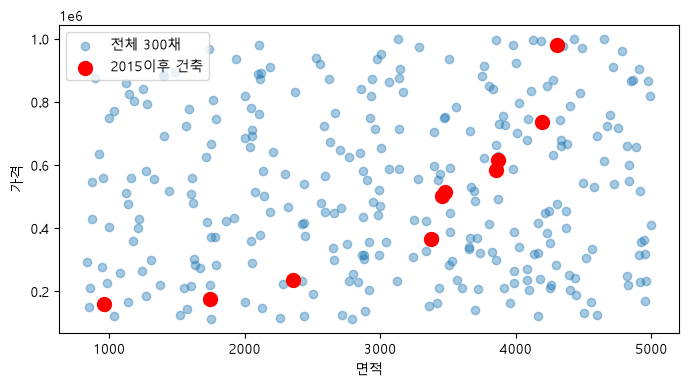

전체 300채의 상관계수: 0.08
2015이후 건축: 0.89


In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
plt.scatter(house["SquareFeet"], house["Price"], alpha=0.4, label="전체 300채")
plt.scatter(small["SquareFeet"], small["Price"], color="red", s=100, label="2015이후 건축")
plt.xlabel("면적")
plt.ylabel("가격")
plt.legend()
plt.show()

print("전체 300채의 상관계수:", round(house["SquareFeet"].corr(house["Price"]),2))
print("2015이후 건축:", round(small["SquareFeet"].corr(small["Price"]), 2))

In [5]:
# 시들: 난수발생 시 참고하는 데이터, 동일한 seed값을 적용하는 항상 동일한 난수가 발생
rng = np.random.default_rng(40)

n = 200
area = rng.uniform(20, 85, n) # 20이상 85 미만에서 균등하게 난수 발생

# y = wx + d
# w : 기울기 450
# b : 절편: 5000
price = (area * 450 + 5000 + rng.normal(0, 2500, n)).round(-1)

# 특이 매물 5건 생성
special = rng.choice(n, 5, replace=False) # replace = False 같은 번호를 중복해서 뽑지 않는다
price[special] += rng.uniform(15000, 25000, 5).round(-1)

office = pd.DataFrame({"area" : area, "price" : price})
office.describe().round(1)

,area,price
count,200.0,200.0
mean,52.8,29138.4
std,18.6,9112.1
min,22.0,11400.0
25%,37.4,21615.0
50%,52.0,28965.0
75%,67.4,36377.5
max,84.9,58460.0


In [6]:
# 파일 저장
office.to_csv("./datasets/office.csv", index=False)

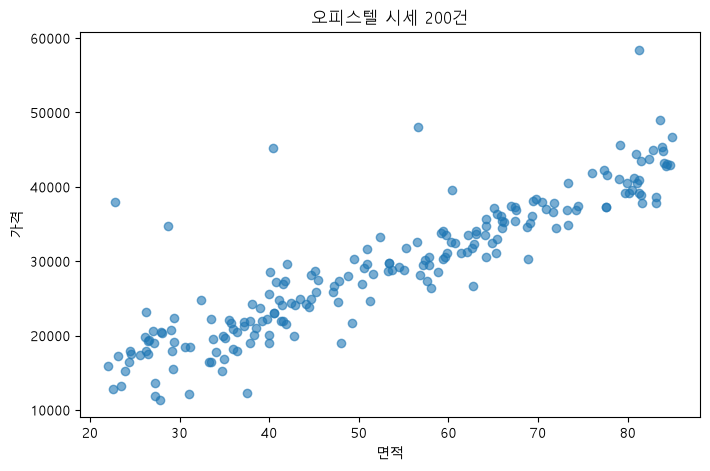

상관계수: 0.8963336215680755


In [7]:
# 산점도 차트

# 캔버스(figsize) 생성
plt.figure(figsize=(8,5))
plt.scatter(office["area"], office["price"], alpha=0.6)
plt.title("오피스텔 시세 200건")
plt.xlabel("면적")
plt.ylabel("가격")
plt.show()

print("상관계수:", office["area"].corr(office["price"]))

In [8]:
from sklearn.linear_model import LinearRegression

X = office[["area"]]
y = office["price"] 
# 선형 회귀 모델 만들기
model = LinearRegression()
# 학습 : X(입력값) , y(정답)
model.fit(X, y)

print(f"기울기 w = {model.coef_[0]} 정답: 450")
print(f"절편 b = {model.intercept_} 정답: 5000")

기울기 w = 439.45870417134705 정답: 450
절편 b = 5926.680580056112 정답: 5000


In [9]:
# 33, 59 가격 예측
new = pd.DataFrame({"area" : [33, 59]})
model.predict(new).round(-1)

array([20430., 31850.])

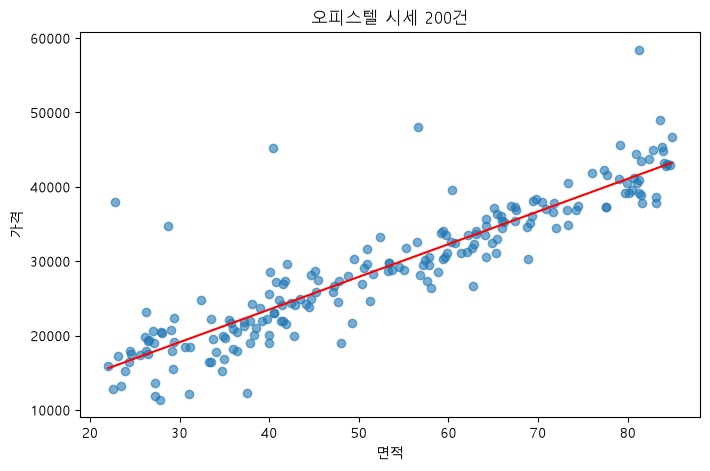

상관계수: 0.8963336215680755


In [10]:
# 학습한 모델로 예측하기
y_pred = model.predict(X)
line = X.sort_values("area")
line_pred = model.predict(line)


# 캔버스(figsize) 생성
plt.figure(figsize=(8,5))
# 산점도 차트
plt.scatter(office["area"], office["price"], alpha=0.6, label="실제 시세")
# 모델의 직선
plt.plot(line["area"], line_pred, color="red", label="모델의 직선")
plt.title("오피스텔 시세 200건")
plt.xlabel("면적")
plt.ylabel("가격")
plt.show()

print("상관계수:", office["area"].corr(office["price"]))

In [11]:
# MAE, MSE, RMSE, R_SCORE
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

# MAE: 오차 절대값의 평균 -> 평균적으로 얼마만큼 틀리나?
print(f"MAE = {mean_absolute_error(y, y_pred):,.0f}")
# MSE: 오차의 제곱의 평균 (단위 제곱)
print(f"MSE = {mean_squared_error(y, y_pred):,.0f}")
# RMWSE: 오차 제곱 평균의 제곱근
print(f"RMSE = {root_mean_squared_error(y, y_pred):,.0f}")
# R_SCORE : 0~1
print(f"R_SCORE = {r2_score(y, y_pred):.3}")




MAE = 2,493
MSE = 16,240,971
RMSE = 4,030
R_SCORE = 0.803


In [12]:
normal = np.ones(len(office), dtype=bool)
normal[special] = False
normal
print("특이매물", special)
print("정상매물", normal.sum())

특이매물 [53 13  2 92 71]
정상매물 195


In [21]:
all_rows = np.ones(len(office), dtype = bool)
cases = [("전체 200건", all_rows), ("특이매물 제외한 195건", normal)]

for name, mask in cases:
    y_true = y[mask]            # 실제 가격
    y_hat = y_pred[mask]        # 예측 가격

    # MAE: 오차 정댓값의 평균
    mae = mean_absolute_error(y_true, y_hat)
    #RMSE
    rmse = root_mean_squared_error(y_true, y_hat)
    # R2
    r2 = r2_score(y_true, y_hat)
    print(f"{name} MAE {mae} | RMSE {rmse} | RScore {r2}")

전체 200건 MAE 2492.503948887723 | RMSE 4030.0088601264406 | RScore 0.8034139611533421
특이매물 제외한 195건 MAE 2075.1039768452683 | RMSE 2731.5353914457346 | RScore 0.9023854405903358
